In [38]:
# Import the libraries required for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the IPL match dataset
df = pd.read_csv('/content/IPL_Matches_Data_2008_2026.csv')
# Keep a copy of the original data before making any changes
df_raw = df.copy()

In [3]:
# Check the number of rows and columns in the dataset
df.shape

(1243, 31)

In [4]:
# View the first five records to understand the data
df.head()

,event_name,season,match_number,date,city,venue,team1,team2,toss_winner,toss_decision,...,umpire2,tv_umpire,reserve_umpire,match_type,overs_limit,balls_per_over,gender,team_type,team1_players,team2_players
0,Indian Premier League,2007/08,1.0,18-04-2008,Bangalore,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,...,RE Koertzen,AM Saheba,VN Kulkarni,T20,20,6,male,club,"R Dravid, W Jaffer, V Kohli, JH Kallis, CL Whi...","SC Ganguly, BB McCullum, RT Ponting, DJ Hussey..."
1,Indian Premier League,2007/08,2.0,19-04-2008,Chandigarh,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,...,SL Shastri,RB Tiffin,MSS Ranawat,T20,20,6,male,club,"K Goel, JR Hopes, KC Sangakkara, Yuvraj Singh,...","PA Patel, ML Hayden, MEK Hussey, MS Dhoni, SK ..."
2,Indian Premier League,2007/08,3.0,19-04-2008,Delhi,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,...,GA Pratapkumar,IL Howell,Unknown,T20,20,6,male,club,"G Gambhir, V Sehwag, S Dhawan, MK Tiwary, KD K...","T Kohli, YK Pathan, SR Watson, M Kaif, DS Lehm..."
3,Indian Premier League,2007/08,4.0,20-04-2008,Kolkata,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,...,K Hariharan,Asad Rauf,F Gomes,T20,20,6,male,club,"WP Saha, BB McCullum, RT Ponting, SC Ganguly, ...","AC Gilchrist, Y Venugopal Rao, VVS Laxman, A S..."
4,Indian Premier League,2007/08,5.0,20-04-2008,Mumbai,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,...,DJ Harper,AV Jayaprakash,SN Bandekar,T20,20,6,male,club,"L Ronchi, ST Jayasuriya, DJ Thornely, RV Uthap...","S Chanderpaul, R Dravid, LRPL Taylor, JH Kalli..."


In [5]:
# Check column names, data types, and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1243 entries, 0 to 1242
Data columns (total 31 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   event_name       1243 non-null   object 
 1   season           1243 non-null   object 
 2   match_number     1169 non-null   float64
 3   date             1243 non-null   object 
 4   city             1243 non-null   object 
 5   venue            1243 non-null   object 
 6   team1            1243 non-null   object 
 7   team2            1243 non-null   object 
 8   toss_winner      1243 non-null   object 
 9   toss_decision    1243 non-null   object 
 10  team1_runs       1243 non-null   int64  
 11  team1_wickets    1243 non-null   int64  
 12  team2_runs       1243 non-null   int64  
 13  team2_wickets    1243 non-null   int64  
 14  winner           1218 non-null   object 
 15  result_type      1243 non-null   object 
 16  win_by_runs      1243 non-null   int64  
 17  win_by_wickets

In [6]:
# Get a statistical summary of the numerical columns
df.describe()

,match_number,team1_runs,team1_wickets,team2_runs,team2_wickets,win_by_runs,win_by_wickets,overs_limit,balls_per_over
count,1169.000000,1243.000000,1243.000000,1243.000000,1243.000000,1243.000000,1243.000000,1243.0,1243.0
mean,31.921300,165.851167,5.956557,157.349155,5.873693,13.932422,3.276750,20.0,6.0
std,18.626023,35.490847,2.309341,34.613073,2.646538,23.861556,3.358216,0.0,0.0
min,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,20.0,6.0
25%,16.000000,144.000000,4.000000,138.000000,4.000000,0.000000,0.000000,20.0,6.0
50%,32.000000,165.000000,6.000000,160.000000,6.000000,0.000000,3.000000,20.0,6.0
75%,47.000000,189.000000,8.000000,179.000000,8.000000,20.000000,6.000000,20.0,6.0
max,72.000000,287.000000,10.000000,265.000000,12.000000,146.000000,10.000000,20.0,6.0


In [7]:
# Check missing values in each column
df.isnull().sum()

,0
event_name,0
season,0
match_number,74
date,0
city,0
venue,0
team1,0
team2,0
toss_winner,0
toss_decision,0


In [8]:
# Check whether the dataset contains duplicate rows
df.duplicated().sum()

np.int64(0)

In [9]:
# Find all the seasons available in the dataset
df['season'].unique()

array(['2007/08', '2009', '2009/10', '2011', '2012', '2013', '2014',
       '2015', '2016', '2017', '2018', '2019', '2020/21', '2021', '2022',
       '2023', '2024', '2025', '2026'], dtype=object)

In [10]:
# Check the result types of matches where the winner is missing
df[df['winner'].isna()]['result_type'].value_counts()

,count
result_type,
tie,16
no result,9


In [11]:
# View matches where the winner is missing
df[df['winner'].isna()][
    ['season', 'date', 'team1', 'team2', 'result_type',
     'win_by_runs', 'win_by_wickets']
]

,season,date,team1,team2,result_type,win_by_runs,win_by_wickets
66,2009,23-04-2009,Kolkata Knight Riders,Rajasthan Royals,tie,0,0
130,2009/10,21-03-2010,Chennai Super Kings,Kings XI Punjab,tie,0,0
241,2011,21-05-2011,Delhi Daredevils,Pune Warriors,no result,0,0
328,2013,07-04-2013,Sunrisers Hyderabad,Royal Challengers Bangalore,tie,0,0
342,2013,16-04-2013,Royal Challengers Bangalore,Delhi Daredevils,tie,0,0
416,2014,29-04-2014,Kolkata Knight Riders,Rajasthan Royals,tie,0,0
475,2015,21-04-2015,Rajasthan Royals,Kings XI Punjab,tie,0,0
485,2015,29-04-2015,Royal Challengers Bangalore,Rajasthan Royals,no result,0,0
511,2015,17-05-2015,Royal Challengers Bangalore,Delhi Daredevils,no result,0,0
610,2017,29-04-2017,Gujarat Lions,Mumbai Indians,tie,0,0


In [12]:
# Check why match numbers are missing
df[df['match_number'].isna()][
    ['season', 'date', 'event_name', 'match_type']
].head(10)

,season,date,event_name,match_type
55,2007/08,30-05-2008,Indian Premier League,T20
56,2007/08,31-05-2008,Indian Premier League,T20
57,2007/08,01-06-2008,Indian Premier League,T20
112,2009,22-05-2009,Indian Premier League,T20
113,2009,23-05-2009,Indian Premier League,T20
114,2009,24-05-2009,Indian Premier League,T20
171,2009/10,21-04-2010,Indian Premier League,T20
172,2009/10,22-04-2010,Indian Premier League,T20
173,2009/10,24-04-2010,Indian Premier League,T20
174,2009/10,25-04-2010,Indian Premier League,T20


In [13]:
# Check the result types of matches with no Player of the Match
df[df['player_of_match'].isna()]['result_type'].value_counts()

,count
result_type,
no result,9


In [14]:
# Check for possible duplicate matches using key match details
df.duplicated(subset=['date', 'team1', 'team2', 'venue']).sum()

np.int64(0)

In [15]:
# Check the distribution of runs and wickets in both innings
df[['team1_runs', 'team2_runs',
    'team1_wickets', 'team2_wickets']].describe()

,team1_runs,team2_runs,team1_wickets,team2_wickets
count,1243.000000,1243.000000,1243.000000,1243.000000
mean,165.851167,157.349155,5.956557,5.873693
std,35.490847,34.613073,2.309341,2.646538
min,2.000000,0.000000,0.000000,0.000000
25%,144.000000,138.000000,4.000000,4.000000
50%,165.000000,160.000000,6.000000,6.000000
75%,189.000000,179.000000,8.000000,8.000000
max,287.000000,265.000000,10.000000,12.000000


In [16]:
# Find matches where Team 2 has more than 10 wickets recorded
df[df['team2_wickets'] > 10][
    ['date', 'team1', 'team2', 'team2_runs',
     'team2_wickets', 'winner', 'result_type','team1_wickets']
]

,date,team1,team2,team2_runs,team2_wickets,winner,result_type,team1_wickets
610,29-04-2017,Gujarat Lions,Mumbai Indians,164,12,NaN,tie,9


In [17]:
# Check whether Team 1 has more than 10 wickets recorded
df[df['team1_wickets'] > 10][
    ['date', 'team1', 'team2', 'team1_wickets']
]

,date,team1,team2,team1_wickets


In [18]:
# Find the 10 matches with the highest combined team scores
df['total_runs'] = df['team1_runs'] + df['team2_runs']

df[['date', 'team1', 'team2',
    'team1_runs', 'team2_runs', 'total_runs']].sort_values(
    'total_runs', ascending=False
).head(10)

,date,team1,team2,team1_runs,team2_runs,total_runs
1053,15-04-2024,Sunrisers Hyderabad,Royal Challengers Bengaluru,287,262,549
1203,25-04-2026,Delhi Capitals,Punjab Kings,264,265,529
1096,23-03-2025,Sunrisers Hyderabad,Rajasthan Royals,286,242,528
1031,27-03-2024,Sunrisers Hyderabad,Mumbai Indians,277,246,523
1065,26-04-2024,Kolkata Knight Riders,Punjab Kings,261,262,523
1066,27-04-2024,Delhi Capitals,Mumbai Indians,257,247,504
1121,12-04-2025,Punjab Kings,Sunrisers Hyderabad,245,247,492
1209,29-04-2026,Mumbai Indians,Sunrisers Hyderabad,243,249,492
1099,25-03-2025,Punjab Kings,Gujarat Titans,243,232,475
1115,08-04-2025,Lucknow Super Giants,Kolkata Knight Riders,238,234,472


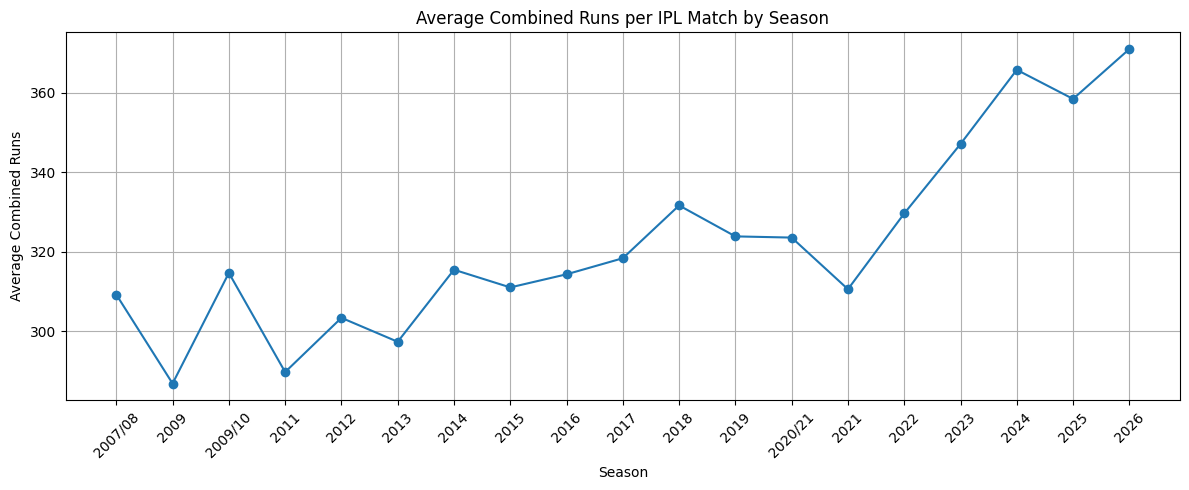

In [19]:
# Calculate the average combined score for each season
season_runs = df.groupby('season')['total_runs'].mean().sort_index()

# Plot the average combined score across seasons
plt.figure(figsize=(12, 5))
plt.plot(season_runs.index,season_runs.values,marker='o')
plt.title('Average Combined Runs per IPL Match by Season')
plt.xlabel('Season')
plt.ylabel('Average Combined Runs')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

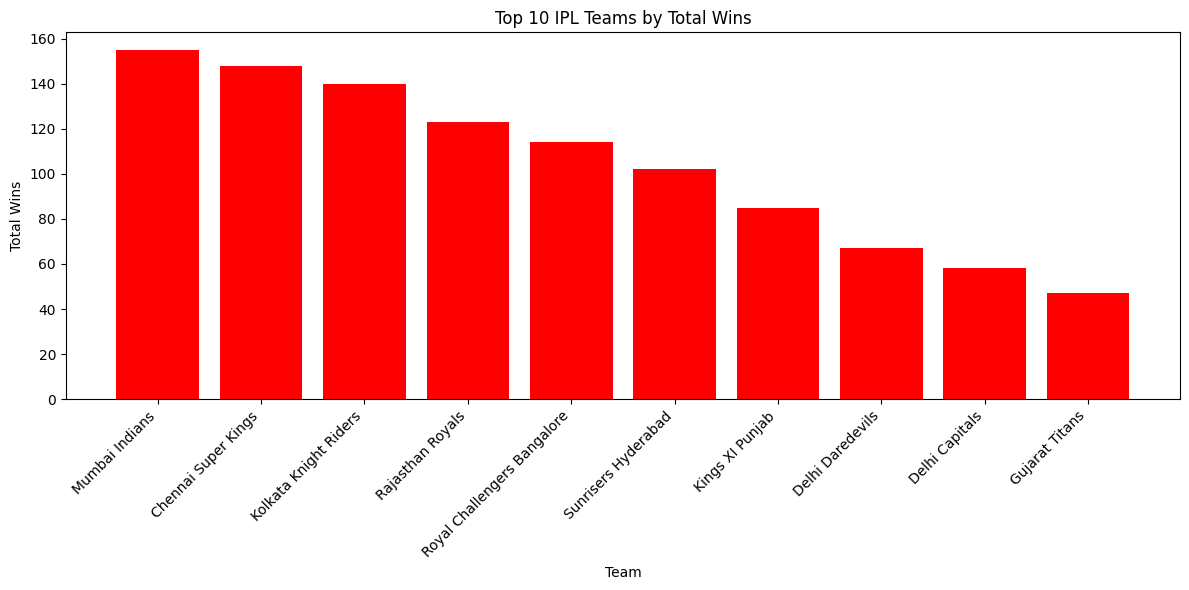

In [20]:
# Count how many matches each team has won
team_wins = df['winner'].value_counts().head(10)

# Create a bar chart
plt.figure(figsize=(12, 6))
plt.bar(team_wins.index,team_wins.values,color='red')

plt.title('Top 10 IPL Teams by Total Wins')
plt.xlabel('Team')
plt.ylabel('Total Wins')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [21]:
# Count Player of the Match awards for each player
player_awards = df['player_of_match'].value_counts()

# Display the top 10 players with the most awards
player_awards.head(10)

,count
player_of_match,
AB de Villiers,25
CH Gayle,22
V Kohli,22
RG Sharma,21
SP Narine,18
DA Warner,18
MS Dhoni,18
RA Jadeja,17
KL Rahul,17


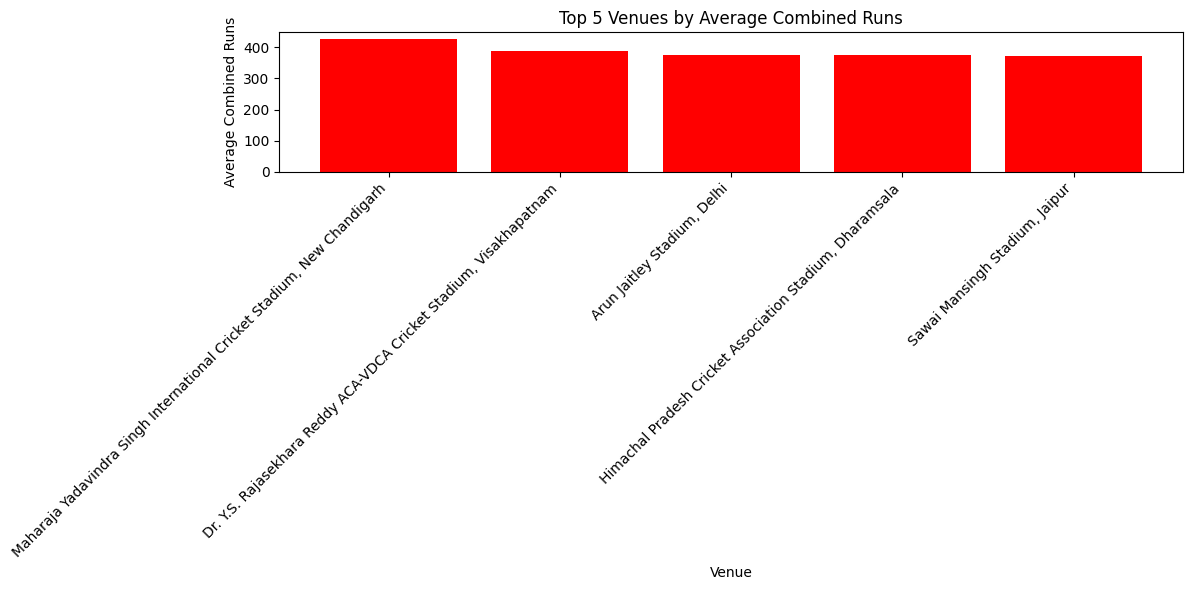

In [22]:
# Calculate the average combined runs for each venue
venue_scores = df.groupby('venue')['total_runs'].mean().sort_values(ascending=False).head(5)

# Select the top 10 venues
top_venues = venue_scores.head(10)

# Create a bar chart
plt.figure(figsize=(12, 6))
plt.bar(venue_scores.index, venue_scores.values, color='red')

plt.title('Top 5 Venues by Average Combined Runs')
plt.xlabel('Venue')
plt.ylabel('Average Combined Runs')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

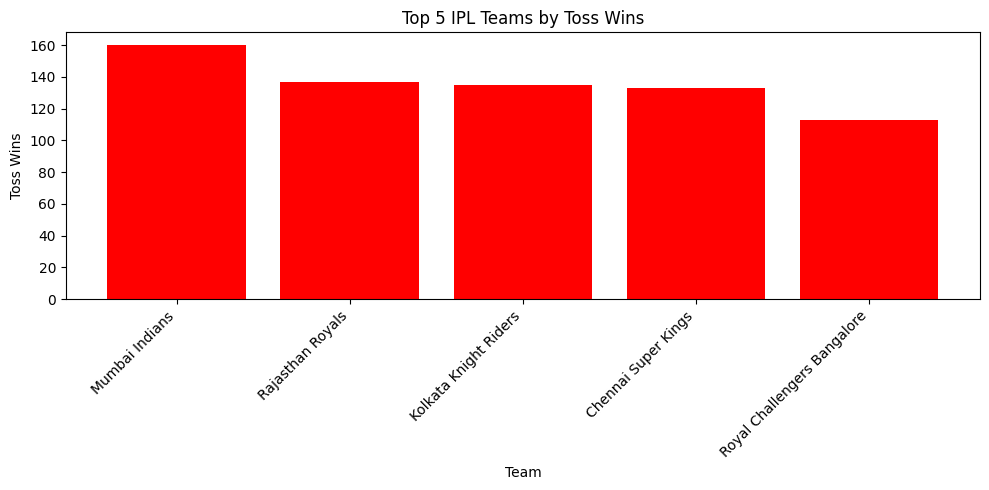

In [23]:
# Count how many times each team won the toss
toss_wins = df['toss_winner'].value_counts()

# Select the top 5 teams
top_toss_wins = toss_wins.head(5)

# Create a bar chart
plt.figure(figsize=(10, 5))
plt.bar(top_toss_wins.index, top_toss_wins.values, color='red')

plt.title('Top 5 IPL Teams by Toss Wins')
plt.xlabel('Team')
plt.ylabel('Toss Wins')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [24]:
# Keep matches where a winner is recorded
completed_matches = df[df['winner'].notna()]

# Count matches where toss winner also won
toss_match_wins = completed_matches[
    completed_matches['toss_winner'] == completed_matches['winner']
]

# Calculate percentage
percentage = (len(toss_match_wins) / len(completed_matches)) * 100

print("Matches with a recorded winner:", len(completed_matches))
print("Toss winner also won:", len(toss_match_wins))
print("Percentage:", round(percentage, 2), "%")

Matches with a recorded winner: 1218
Toss winner also won: 628
Percentage: 51.56 %


In [25]:
# Keep matches where a winner is recorded
completed_matches = df[df['winner'].notna()]

# Select matches where toss winner chose to bat
bat_matches = completed_matches[completed_matches['toss_decision'] == 'bat']

# Count matches where toss winner also won
bat_wins = bat_matches[bat_matches['toss_winner'] == bat_matches['winner']]

# Calculate win percentage
print("Toss decision: Bat")
print("Total matches:", len(bat_matches))
print("Toss winner also won:", len(bat_wins))
print("Win percentage:", round(len(bat_wins) / len(bat_matches) * 100, 2), "%")

Toss decision: Bat
Total matches: 408
Toss winner also won: 185
Win percentage: 45.34 %


In [27]:
# Select matches where toss winner chose to bowl
bowl_matches = completed_matches[completed_matches['toss_decision'] == 'field']

# Count matches where toss winner also won
bowl_wins = bowl_matches[bowl_matches['toss_winner'] == bowl_matches['winner']]

# Calculate win percentage
print("Toss decision: Bowl")
print("Total matches:", len(bowl_matches))
print("Toss winner also won:", len(bowl_wins))
print("Win percentage:", round(len(bowl_wins) / len(bowl_matches) * 100, 2), "%")

Toss decision: Bowl
Total matches: 810
Toss winner also won: 443
Win percentage: 54.69 %


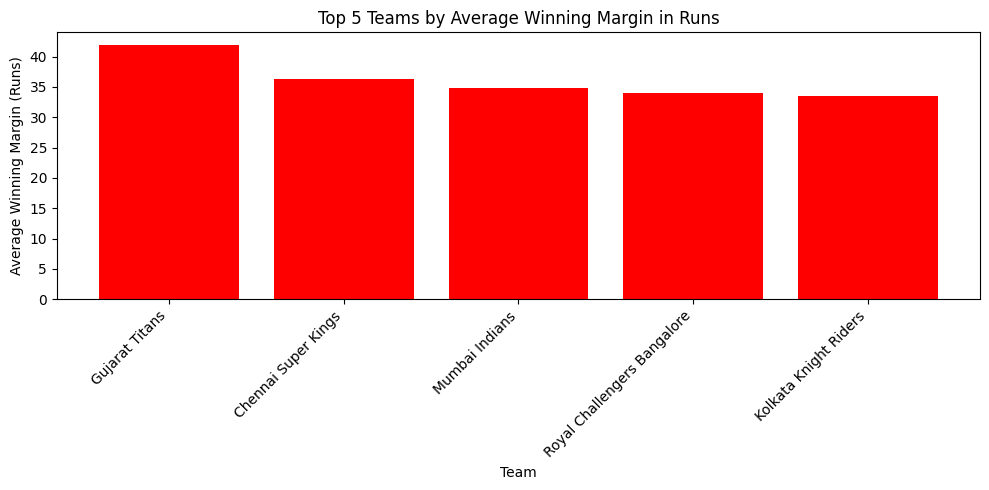

In [34]:
# Keep completed matches with a winning margin greater than 0 runs
run_wins = df[(df['result_type'] == 'complete') & (df['win_by_runs'] > 0)]

# Calculate average winning margin by runs for each team
avg_margin = run_wins.groupby('winner')['win_by_runs'].mean().sort_values(ascending=False).head(5)

# Create a bar chart
plt.figure(figsize=(10, 5))
plt.bar(avg_margin.index, avg_margin.values, color='red')

plt.title('Top 5 Teams by Average Winning Margin in Runs')
plt.xlabel('Team')
plt.ylabel('Average Winning Margin (Runs)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

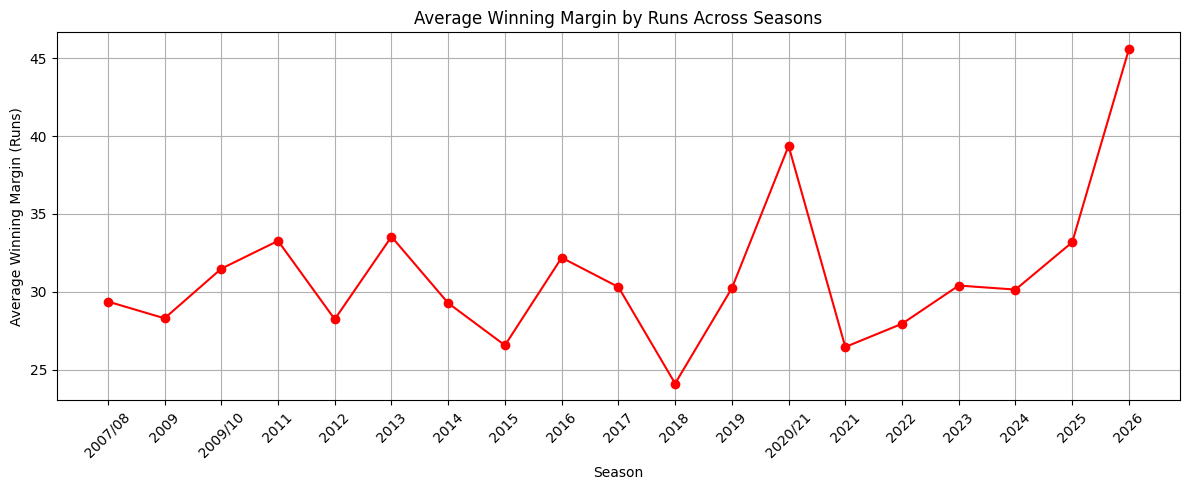

In [35]:
# Keep matches with a recorded winner and a positive run margin
run_wins = df[(df['winner'].notna()) & (df['win_by_runs'] > 0)]

# Calculate average winning margin for each season
season_margin = run_wins.groupby('season')['win_by_runs'].mean().sort_index()

# Create a line chart
plt.figure(figsize=(12, 5))
plt.plot(season_margin.index, season_margin.values, marker='o', color='red')

plt.title('Average Winning Margin by Runs Across Seasons')
plt.xlabel('Season')
plt.ylabel('Average Winning Margin (Runs)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

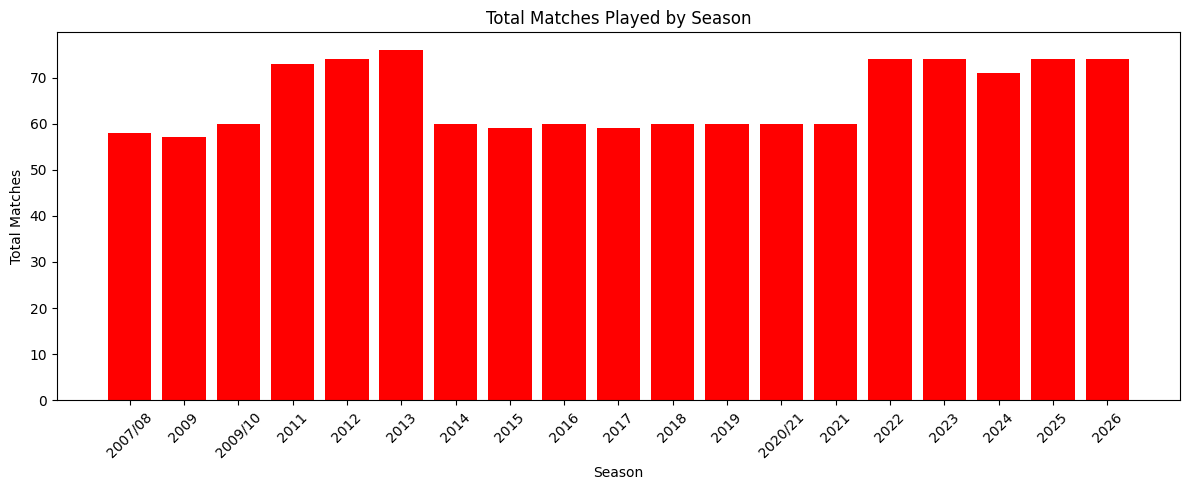

In [36]:
# Count matches in each season
season_matches = df.groupby('season')['event_name'].count().sort_index()

# Create a bar chart
plt.figure(figsize=(12, 5))
plt.bar(season_matches.index, season_matches.values, color='red')

plt.title('Total Matches Played by Season')
plt.xlabel('Season')
plt.ylabel('Total Matches')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

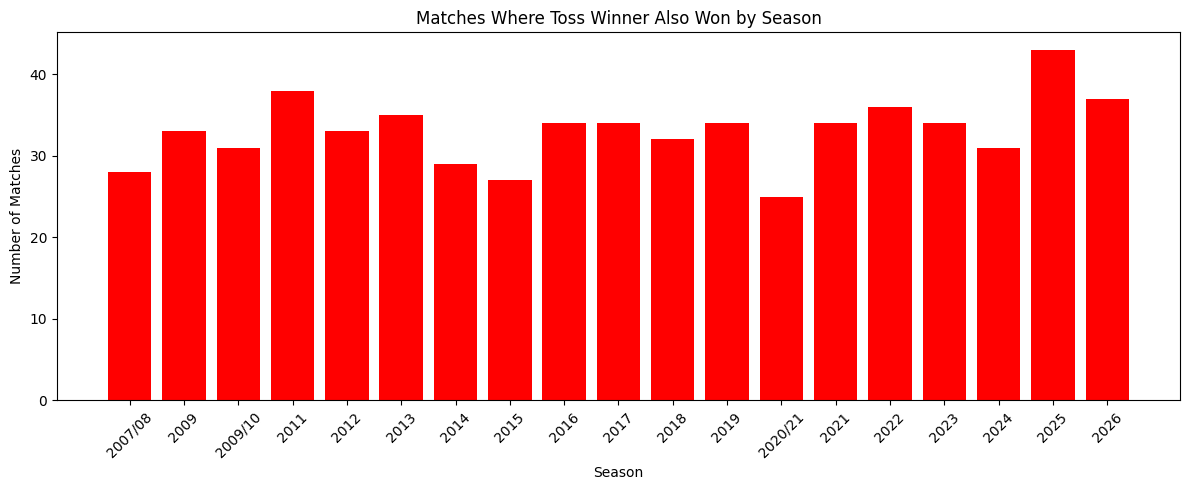

In [37]:
# Keep matches where a winner is recorded
completed_matches = df[df['winner'].notna()]

# Keep matches where toss winner also won
toss_wins = completed_matches[
    completed_matches['toss_winner'] == completed_matches['winner']
]

# Count these matches in each season
season_toss_wins = toss_wins.groupby('season')['winner'].count().sort_index()

# Create a bar chart
plt.figure(figsize=(12, 5))
plt.bar(season_toss_wins.index, season_toss_wins.values, color='red')

plt.title('Matches Where Toss Winner Also Won by Season')
plt.xlabel('Season')
plt.ylabel('Number of Matches')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()